# 5. Clasificación: resultados de las combinaciones

*Autores: María Carolina Cantillo Orozco (200179105) y Juan Camilo Oñoro Araujo (200177329)*

```{admonition} Qué responde este capítulo
:class: tip
**Pregunta.** ¿Qué combinación de modelo, balanceo y optimizador clasifica mejor el estrato, en validación y en
el test, y qué tan confiables son sus probabilidades?

**Respuesta corta.** En validación ganan los tres ensambles de árboles (Random Forest, XGBoost y XGBoost
geográfico, F1 ≈ 0.66). En el test empatan la logística con vecindad (0.572), XGBoost y Random Forest, y todos
los finalistas menos Naive Bayes superan al modelo base (0.428). `class_weight` es el mejor balanceo y ADASYN el
peor. XGBoost, KNN y la logística salen bien calibrados; Platt o la regresión isotónica corrigen a los demás.
```

## 5.1 Métrica principal: F1 macro

El estrato tiene seis clases muy desbalanceadas (6.2 a 1). La **accuracy** premia acertar los estratos grandes:
un modelo que nunca predice el 6 puede tener buena accuracy. El **F1 macro** promedia el F1 de cada estrato sin
ponderar por su tamaño, así que el estrato 6 pesa tanto como el 1, y combina precisión y recall: penaliza tanto
los falsos positivos (asignar un estrato alto a una vivienda que no lo es, que en una aplicación de subsidios
quitaría el beneficio a quien lo necesita) como los falsos negativos (no reconocer un estrato bajo). Por eso es el
criterio de selección en todo el proyecto. Se reportan además AUC (capacidad de ordenar), métricas ordinales
(MAE, accuracy ±1, kappa cuadrático: un error de un estrato no es igual que uno de cuatro) y de calibración
(Brier, ECE).

## 5.2 Las 128 combinaciones en el bucle externo

Media ± desviación estándar entre los 5 pliegues externos (validación anidada):

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from _comun import figura, leer_csv, leer_json

R = leer_csv("resumen_combinaciones.csv")
A = leer_json("analisis_clasificacion.json") or {}
if R is not None:
    cols = ["modelo", "balanceo", "metodo", "f1_macro_mean", "f1_macro_std", "accuracy_mean", "precision_macro_mean",
            "recall_macro_mean", "auc_ovr_mean", "mae_ordinal_mean", "seg_busqueda_mean"]
    t = R[cols].copy()
    t.columns = ["modelo", "balanceo", "optimizador", "F1 macro", "± desv.", "accuracy", "precision", "recall", "AUC",
                 "MAE ordinal", "segundos de búsqueda"]
    display(t.head(20).round(3))

,modelo,balanceo,optimizador,F1 macro,± desv.,accuracy,precision,recall,AUC,MAE ordinal,segundos de búsqueda
0,Random Forest,smote,Genética,0.658,0.069,0.719,0.711,0.677,0.935,0.322,387.874
1,XGBoost,smote,Random,0.656,0.071,0.720,0.669,0.670,0.930,0.321,299.910
2,XGBoost,smote,Bayesiana,0.656,0.068,0.718,0.673,0.673,0.930,0.321,260.990
3,XGBoost geográfico,class_weight,Bayesiana,0.656,0.063,0.723,0.678,0.668,0.931,0.320,230.769
4,Random Forest,class_weight,Random,0.655,0.066,0.730,0.709,0.667,0.935,0.313,212.193
5,Random Forest,class_weight,Genética,0.653,0.064,0.725,0.704,0.664,0.933,0.319,217.451
6,XGBoost,smote,Genética,0.653,0.063,0.720,0.665,0.668,0.930,0.316,347.007
7,Random Forest,smote,Random,0.653,0.085,0.722,0.701,0.668,0.933,0.328,449.585
8,Random Forest,class_weight,Grid,0.651,0.063,0.725,0.704,0.663,0.936,0.318,241.754
9,Random Forest,adasyn,Bayesiana,0.651,0.082,0.720,0.704,0.668,0.936,0.325,317.813


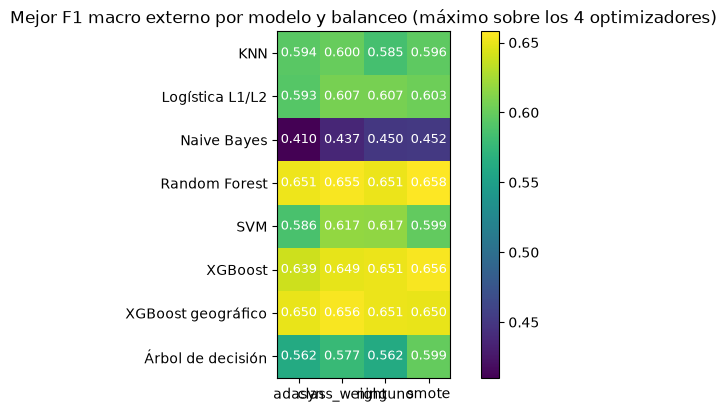

In [2]:
if R is not None:
    piv = R.pivot_table(index="modelo", columns="balanceo", values="f1_macro_mean", aggfunc="max")
    fig, ax = plt.subplots(figsize=(8, 4.5))
    im = ax.imshow(piv.to_numpy(), cmap="viridis")
    ax.set_xticks(range(piv.shape[1]), piv.columns)
    ax.set_yticks(range(piv.shape[0]), piv.index)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f"{piv.iat[i, j]:.3f}", ha="center", va="center", color="white", fontsize=9)
    ax.set_title("Mejor F1 macro externo por modelo y balanceo (máximo sobre los 4 optimizadores)")
    plt.colorbar(im)
    plt.show()

**Lectura.** El modelo pesa mucho más que el balanceo o el optimizador. El mejor F1 macro externo de cada
modelo va de 0.452 (Naive Bayes) a 0.658 (Random Forest), mientras que dentro de un mismo modelo las 16
combinaciones de balanceo y optimizador se separan entre 0.02 y 0.05 (0.08 en el árbol, el modelo más sensible
a sus hiperparámetros). Arriba quedan los tres ensambles de árboles: Random Forest (0.658), XGBoost (0.656) y
XGBoost geográfico (0.656), con AUC de 0.93 y un MAE ordinal de 0.32 estratos. En el medio, SVM (0.617), la
logística (0.607), KNN (0.600) y el árbol (0.599); al final, Naive Bayes, cuyo supuesto de independencia choca
con variables muy correlacionadas (área, baños, habitaciones; las de vecindad entre sí).

La desviación entre pliegues externos (0.06 a 0.09) es mayor que las diferencias entre las mejores
combinaciones: ninguna conclusión fina sale de esta tabla sola. Por eso las comparaciones se hacen con pruebas
pareadas (capítulo 7). Los errores son casi siempre de un estrato: la accuracy ±1 de los ensambles es 0.96.

## 5.3 Balanceo de clases

**SMOTE** genera viviendas sintéticas interpolando entre una vivienda minoritaria y uno de sus 5 vecinos de la
misma clase. **ADASYN** genera más ejemplos alrededor de las viviendas minoritarias difíciles (las rodeadas de
otras clases). **`class_weight='balanced'`** no inventa datos: pesa cada error por el inverso de la frecuencia de
su clase. Las tres se aplican solo dentro del entrenamiento de cada pliegue.

In [3]:
if A.get("balanceo"):
    b = pd.DataFrame(A["balanceo"]).T
    display(b[[c for c in b.columns if c.endswith("_mean")]].round(4))
if A.get("friedman_balanceo"):
    f = A["friedman_balanceo"]
    print(f"Friedman entre técnicas de balanceo (n = {f['n_bloques']} bloques modelo × optimizador × pliegue): "
          f"χ² = {f['chi2']:.2f}, p = {f['p']:.4g}; rangos (1 = mejor): {f['rangos']}")

,f1_macro_mean,recall_macro_mean,auc_ovr_mean,ece_mean,seg_busqueda_mean
adasyn,0.5787,0.6067,0.8911,0.1642,285.6200
class_weight,0.5930,0.6180,0.8997,0.1529,136.2538
ninguno,0.5901,0.6043,0.8985,0.1457,140.5465
smote,0.5905,0.6159,0.8934,0.1598,259.0979


Friedman entre técnicas de balanceo (n = 160 bloques modelo × optimizador × pliegue): χ² = 29.39, p = 1.852e-06; rangos (1 = mejor): {'class_weight': 2.25, 'smote': 2.388, 'ninguno': 2.394, 'adasyn': 2.969}


**Lectura.** Friedman detecta diferencias entre técnicas (p = 2·10⁻⁶), pero son pequeñas y no todas a favor
del balanceo:

- **`class_weight`** es la mejor (rango medio 2.25 de 4; F1 0.593, recall macro 0.618) y la más barata: no agrega
  filas, así que la búsqueda cuesta lo mismo que sin balanceo (136 s frente a 141 s).
- **SMOTE** empata con no balancear en F1 (0.591 frente a 0.590) y sube algo el recall (0.616 frente a 0.604), pero
  casi duplica el tiempo de búsqueda (259 s), porque entrena con unas 1.8 veces más filas.
- **ADASYN** es la peor (rango 2.97; F1 0.579) y la más cara (286 s). Concentra los ejemplos sintéticos en las
  viviendas «difíciles», las rodeadas de otros estratos; aquí son, sobre todo, las de las fronteras entre barrios, donde
  el estrato cambia de una cuadra a otra, así que probablemente ADASYN refuerza justo el ruido.

Todas las técnicas empeoran algo la calibración (ECE 0.146 sin balanceo; 0.153 a 0.164 con balanceo): al
cambiar las proporciones de entrenamiento, las probabilidades dejan de reflejar las frecuencias reales. El
desbalance del estrato (6.2 a 1) es moderado y los ensambles lo manejan bien; por eso el balanceo aporta poco.

## 5.4 Finalistas en el test

Para cada modelo se toma su mejor combinación, se repite su búsqueda en toda la submuestra y se evalúa **una vez**
en el test del Entregable 1 (los mismos 7 bloques de 2 km). Intervalos BCa remuestreando los bloques de test.
Como referencia se agrega el **modelo base del Entregable 1** (logística B: C = 0.01, sin pesos y **sin** las
variables de vecindad), entrenado con la misma submuestra.

,balanceo,optimizador,accuracy,precision,recall,F1 macro,IC 95 % BCa,AUC,MAE ordinal
Logística L1/L2,ninguno,Bayesiana,0.695,0.570,0.595,0.572,"[0.549, 0.604]",0.929,0.325
XGBoost,smote,Random,0.696,0.605,0.561,0.566,"[0.536, 0.756]",0.935,0.312
Random Forest,smote,Genética,0.694,0.578,0.553,0.557,"[0.523, 0.714]",0.934,0.315
KNN,class_weight,Bayesiana,0.649,0.541,0.590,0.536,"[0.513, 0.718]",0.914,0.378
XGBoost geográfico,class_weight,Bayesiana,0.656,0.595,0.526,0.522,"[0.459, 0.714]",0.932,0.355
SVM,class_weight,Grid,0.542,0.488,0.501,0.485,"[0.362, 0.552]",0.871,0.482
Árbol de decisión,smote,Grid,0.622,0.486,0.494,0.485,"[0.454, 0.531]",0.767,0.425
Logística B (modelo base del E1),ninguno,fijo (E1: C = 0.01),0.618,0.477,0.443,0.428,"[0.398, 0.480]",0.895,0.442
Naive Bayes,smote,Bayesiana,0.481,0.473,0.485,0.387,"[0.293, 0.455]",0.875,0.583


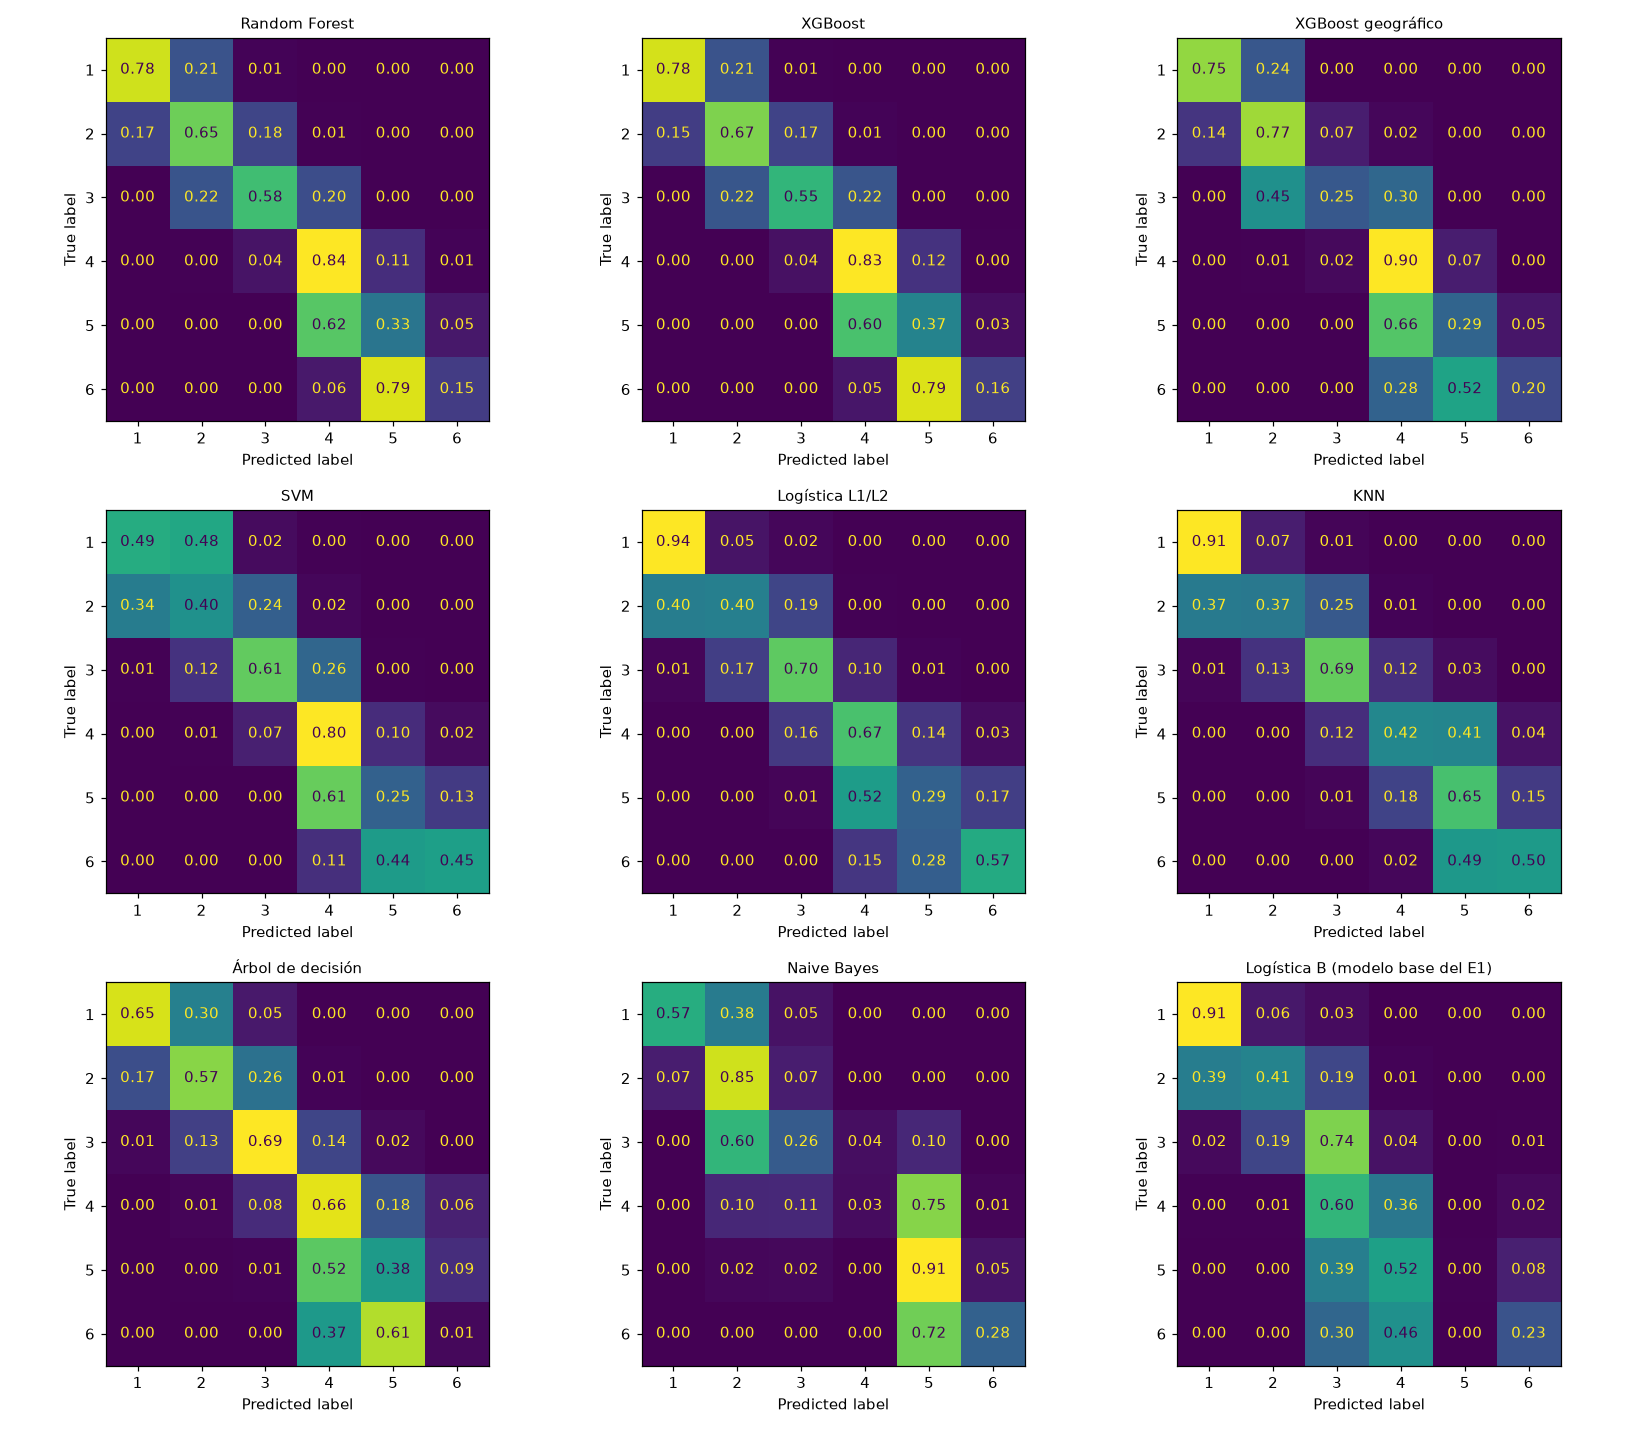

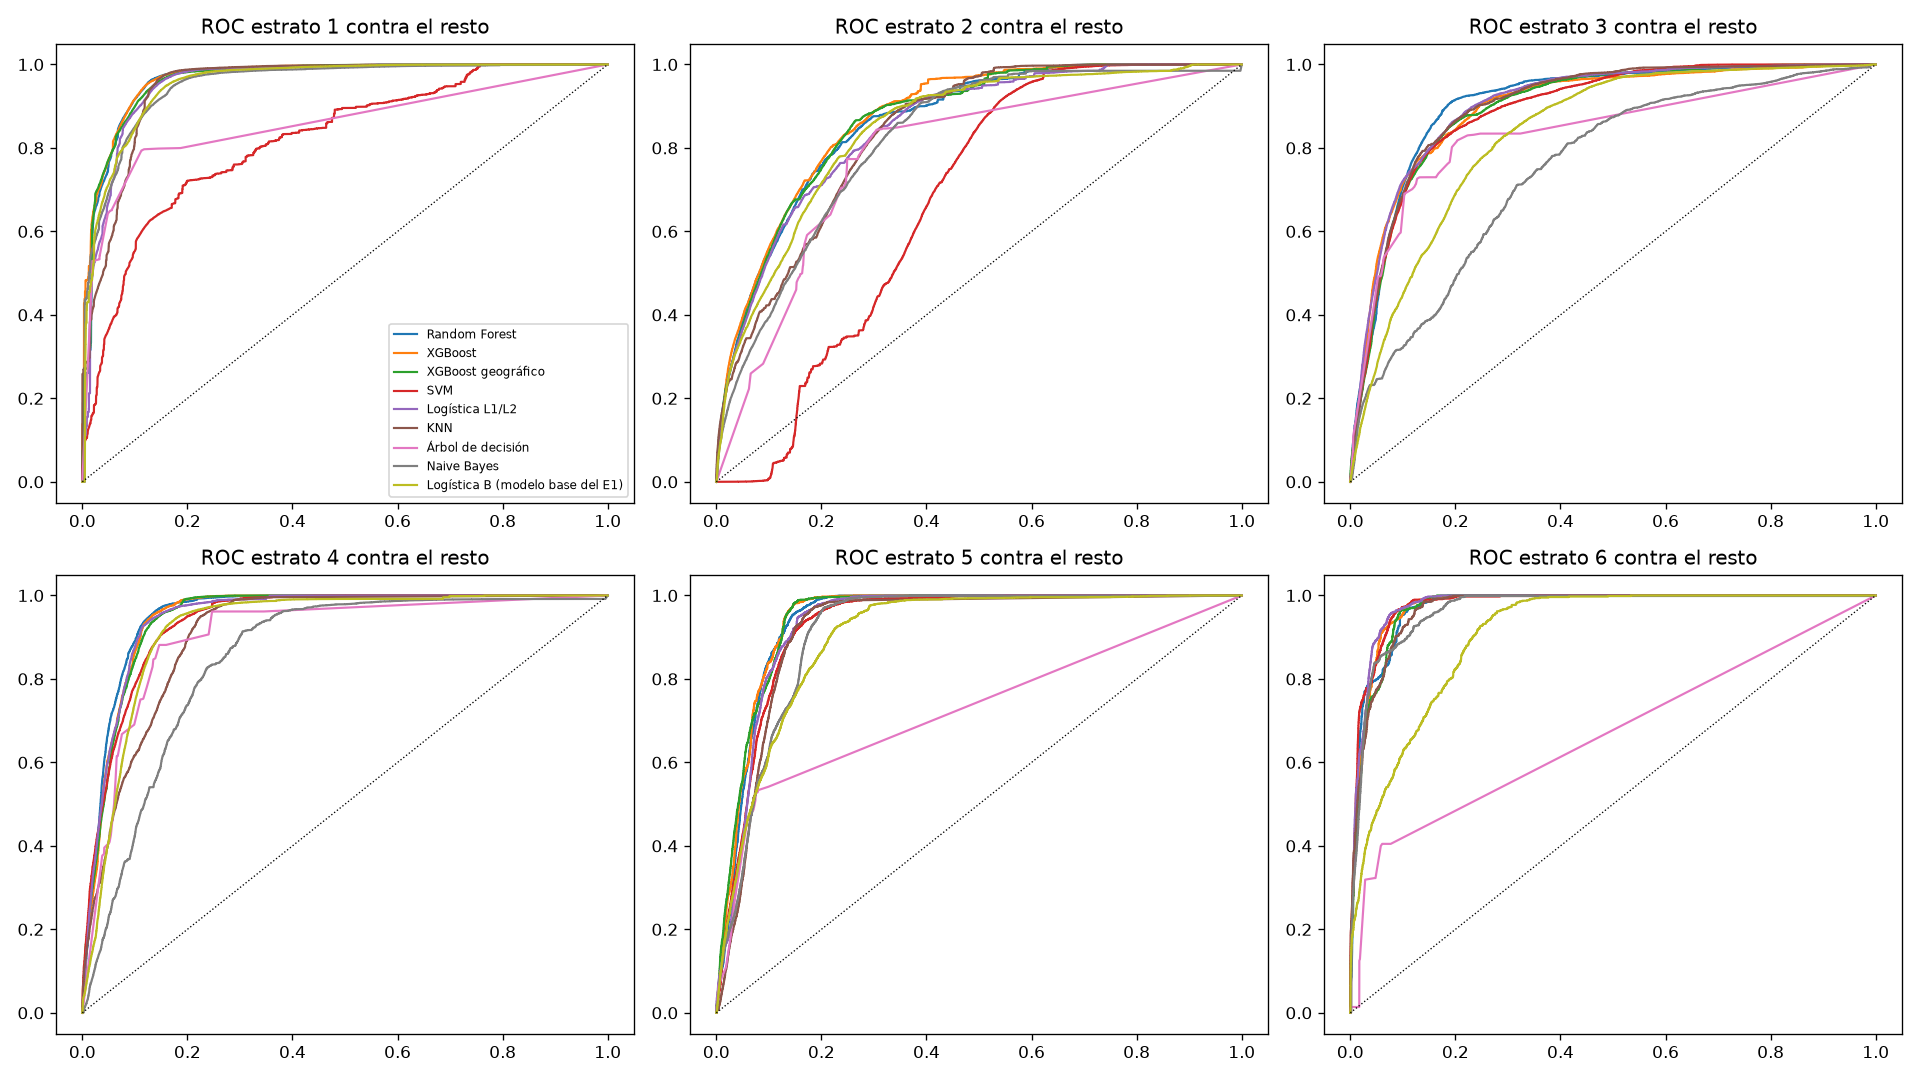

In [4]:
FN = leer_json("finalistas.json")
if FN:
    ft = pd.DataFrame({n: {"balanceo": v["balanceo"], "optimizador": v["metodo"], "accuracy": v["test"]["accuracy"],
                           "precision": v["test"]["precision_macro"], "recall": v["test"]["recall_macro"],
                           "F1 macro": v["test"]["f1_macro"], "IC 95 % BCa": f"[{v['ic95_bca_f1_test'][0]:.3f}, "
                                                                            f"{v['ic95_bca_f1_test'][1]:.3f}]",
                           "AUC": v["test"]["auc_ovr"], "MAE ordinal": v["test"]["mae_ordinal"]}
                       for n, v in FN["finalistas"].items()}).T
    if FN.get("modelo_base"):
        b = FN["modelo_base"]
        ft.loc[b["nombre"]] = {"balanceo": "ninguno", "optimizador": "fijo (E1: C = 0.01)",
                               "accuracy": b["test"]["accuracy"], "precision": b["test"]["precision_macro"],
                               "recall": b["test"]["recall_macro"], "F1 macro": b["test"]["f1_macro"],
                               "IC 95 % BCa": f"[{b['ic95_bca_f1_test'][0]:.3f}, {b['ic95_bca_f1_test'][1]:.3f}]",
                               "AUC": b["test"]["auc_ovr"], "MAE ordinal": b["test"]["mae_ordinal"]}
    num = ["accuracy", "precision", "recall", "F1 macro", "AUC", "MAE ordinal"]
    ft[num] = ft[num].astype(float).round(3)
    display(ft.sort_values("F1 macro", ascending=False))
figura("confusion_finalistas.png")
figura("roc_finalistas.png")

**Lectura.** En el test todos bajan respecto al bucle externo (los ensambles, de ≈ 0.66 a 0.52–0.57) y el
orden cambia. La **logística con vecindad** queda primera (F1 0.572, IC [0.549, 0.604]), muy cerca de XGBoost
(0.566) y Random Forest (0.557); KNN sigue con 0.536 y el XGBoost geográfico cae a 0.522. Con solo 7 bloques,
los intervalos BCa son anchos y asimétricos y se solapan entre los cinco primeros. El modelo base del
Entregable 1 (sin vecindad) queda en 0.428: **todos los finalistas menos Naive Bayes lo superan**, y la
diferencia la explica sobre todo la vecindad física, que comparten todos.

El orden lo deciden los estratos de los extremos (matrices de confusión normalizadas por fila):

- **Estrato 6.** La logística reconoce el 57 %; los ensambles de árboles, solo el 15 % al 20 %, y mandan casi
  todo lo demás al 5 (79 % en XGBoost y Random Forest). En el test hay muy pocas viviendas de estrato 6 (793, el
  1.2 %, frente al 4.8 % de la submuestra de entrenamiento), así que un recall bajo en esa clase hunde el F1 macro
  aunque casi no mueva la accuracy.
- **Estrato 1.** La logística acierta el 94 %; los árboles, el 75 % al 78 % (el resto va al 2).
- A cambio, los árboles son mejores en los estratos 2 y 4 (por ejemplo, 0.83 a 0.90 de recall en el 4, frente a
  0.67 de la logística). El XGBoost geográfico, además, pierde el estrato 3 (recall 0.25: lo reparte entre el 2 y
  el 4).

Casi todos los errores siguen siendo de un estrato: la accuracy ±1 es 0.97 a 0.99 en los cinco primeros, y el
MAE ordinal va de 0.31 (XGBoost) a 0.38 (KNN).

## 5.5 Calibración de probabilidades

Un AUC alto dice que el modelo **ordena** bien, no que sus probabilidades sean creíbles. El diagrama de
confiabilidad compara la confianza predicha con la proporción real de aciertos; el **Brier** es el error
cuadrático de las probabilidades y el **ECE** la distancia media entre confianza y acierto (10 intervalos).
Cuando la calibración es mala se recalibra con **Platt** (una sigmoide sobre los puntajes) o **regresión
isotónica** (una función monótona libre), ajustadas con validación cruzada dentro de la submuestra.

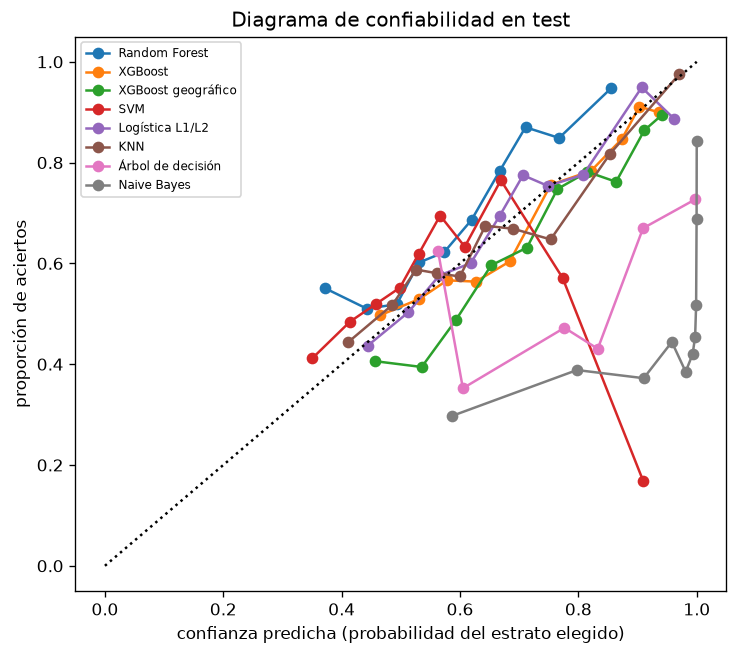

,Brier original,ECE original,Brier Platt,ECE Platt,Brier isotónica,ECE isotónica
Random Forest,0.4240,0.0909,0.3962,0.0444,0.3913,0.0512
XGBoost,0.4085,0.0290,0.4149,0.0371,0.4022,0.0359
XGBoost geográfico,0.4513,0.0683,0.4364,0.0319,0.4182,0.0457
SVM,0.6352,0.1518,0.5342,0.0683,0.5374,0.0635
Logística L1/L2,0.4136,0.0173,0.5068,0.2233,0.4892,0.1660
KNN,0.4702,0.0291,0.4672,0.0363,0.4519,0.0289
Árbol de decisión,0.6127,0.2334,0.5035,0.1286,0.4893,0.1240
Naive Bayes,0.9128,0.4415,0.6028,0.0859,0.5431,0.0437


In [5]:
figura("confiabilidad_finalistas.png")
if FN:
    cal = FN["calibracion"]
    display(pd.DataFrame({n: {"Brier original": c["original"]["brier"], "ECE original": c["original"]["ece"],
                              "Brier Platt": c["platt"]["brier"], "ECE Platt": c["platt"]["ece"],
                              "Brier isotónica": c["isotonica"]["brier"], "ECE isotónica": c["isotonica"]["ece"]}
                          for n, c in cal.items()}).T.round(4))

**Lectura.** Tres modelos ya salen bien calibrados: la logística (ECE 0.017), KNN (0.029) y XGBoost (0.029).
Los peor calibrados son los esperados: Naive Bayes (ECE 0.44: su supuesto de independencia multiplica
evidencias correlacionadas y lo vuelve extremadamente confiado), el árbol (0.23: sus hojas dan probabilidades
de 0 o 1), SVM (0.15: sus «probabilidades» son un softmax de distancias al hiperplano) y, en menor medida,
Random Forest (0.091) y el XGBoost geográfico (0.068).

La recalibración arregla a los mal calibrados: Naive Bayes baja a ECE 0.044 con regresión isotónica (Brier de
0.913 a 0.543), el árbol a 0.124, SVM a 0.063, Random Forest a 0.044 con Platt y el XGBoost geográfico a 0.032
con Platt. En los que ya estaban bien no ayuda o empeora: XGBoost pasa de 0.029 a 0.036–0.037, y la logística
se **descalibra** (ECE 0.17–0.22, y su F1 cae a 0.49–0.53). `CalibratedClassifierCV` recalibra cada estrato
contra el resto y luego renormaliza, lo que deforma un softmax que ya era coherente.

Un efecto lateral útil: como el recalibrado promedia los 5 modelos de los pliegues, también cambia las
decisiones. El F1 de test sube en Random Forest (0.557 → 0.579 con Platt), en el XGBoost geográfico (0.522 →
0.555–0.558) y en Naive Bayes (0.387 → 0.444). Aun así, el XGBoost geográfico recalibrado queda por debajo de
la logística sin recalibrar (0.572).

## 5.6 Robustez: pliegues y semillas

La desviación entre pliegues externos aparece en la tabla de 5.2. Para los modelos con aleatoriedad se
reentrenó el finalista con 5 semillas distintas (1, 7, 42, 123, 2026):

In [6]:
if FN and FN.get("semillas"):
    display(pd.DataFrame({n: {"F1 medio": v["media"], "desv. entre semillas": v["sd"]}
                          for n, v in FN["semillas"].items()}).T.round(4))

,F1 medio,desv. entre semillas
Random Forest,0.5706,0.0134
XGBoost,0.5715,0.0058
XGBoost geográfico,0.5275,0.0074
SVM,0.4842,0.0082


**Lectura.** Cambiar la semilla mueve el F1 de test entre 0.006 (XGBoost) y 0.013 (Random Forest; con la
semilla 42 dio 0.557, pero la media de las 5 semillas es 0.571). Es menos que la distancia del XGBoost
geográfico a los demás ensambles (0.035 a 0.050), pero del mismo orden que las diferencias entre los tres
primeros (logística 0.572, XGBoost 0.571 y Random Forest 0.571 de media): **en el test, esos tres empatan**.
La variación entre pliegues externos (desviación de 0.06 a 0.09) es todavía mayor, y por eso las comparaciones
se resuelven con pruebas pareadas por bloque o por pliegue (capítulo 7 y sección 9.3), no comparando medias
sueltas.